In [3]:
!git clone https://gitee.com/paddlepaddle/PaddleSeg.git 
!pip install -r PaddleSeg/requirements.txt 
!git clone https://gitee.com/paddlepaddle/PaddleDetection.git
!pip install -r PaddleDetection/requirements.txt 

fatal: destination path 'PaddleSeg' already exists and is not an empty directory.


fatal: destination path 'PaddleDetection' already exists and is not an empty directory.


修改PaddleDetection/configs/datasets/coco_detection.yml,调整训练集和验证集路径：

修改PaddleDetection/configs/ppyolo/base/optimizer_1x.yml, 修改学习率，如果是单卡训练，建议适当降低base_lr以及steps，不然在训练过程中可能会出现loss消失现象，导致模型无法收敛：

在训练中交替执行评估, 评估在每个epoch训练结束后开始。每次评估后还会评出最佳mAP模型保存到best_model文件夹下。 如果验证集很大，测试将会比较耗时，建议调整configs/runtime.yml 文件中的 snapshot_epoch配置以减少评估次数，或训练完成后再进行评估。

In [10]:
!python PaddleDetection/tools/train.py \
	-c PaddleDetection/configs/ppyolo/ppyolo_r50vd_dcn_1x_coco.yml \
    --use_vdl=true  \
    --vdl_log_dir=PaddleDetection/vdl_dir/scalar \
    --eval

loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
[06/23 19:30:30] ppdet.data.source.coco INFO: Load [725 samples valid, 0 samples invalid] in file data/meter_det\annotations/instance_train.json.
[06/23 19:30:35] ppdet.utils.checkpoint INFO: Finish loading model weights: C:\Users\z1586_um4y6b2/.cache/paddle/weights\ResNet50_vd_ssld_pretrained.pdparams
[06/23 19:30:40] ppdet.engine INFO: Epoch: [0] [ 0/72] learning_rate: 0.000000 loss_xy: 1.972785 loss_wh: 4.937606 loss_iou: 5.435008 loss_iou_aware: 0.879378 loss_obj: 4803.585938 loss_cls: 1.378438 loss: 4818.188965 eta: 0:12:07 batch_cost: 5.0507 data_cost: 0.0000 ips: 1.9799 images/s
[06/23 19:32:29] ppdet.engine INFO: Epoch: [0] [20/72] learning_rate: 0.000004 loss_xy: 1.321943 loss_wh: 3.438965 loss_iou: 4.813636 loss_iou_aware: 0.926235 loss_obj: 2167.978088 loss_cls: 1.063554 loss: 2181.533142 eta: 0:11:11 batch_cost: 5.4349 data_cost: 0.0002 ips: 1.8399 images/s
[06/23 19:34:09] ppdet.engine INFO:

W0623 19:30:30.797173  9104 gpu_resources.cc:119] Please NOTE: device: 0, GPU Compute Capability: 8.6, Driver API Version: 12.3, Runtime API Version: 11.7
W0623 19:30:30.817620  9104 gpu_resources.cc:149] device: 0, cuDNN Version: 8.4.


visualdl --logdir PaddleDetection/vdl_dir/scalar/

导出模型

In [19]:
!python PaddleDetection/tools/export_model.py \
	-c PaddleDetection/configs/ppyolo/ppyolo_r50vd_dcn_1x_coco.yml \
    --output_dir=./inference_model \
 	-o weights=PaddleDetection/output/ppyolo_r50vd_dcn_1x_coco/model_final/best_model.pdparams

Traceback (most recent call last):
  File "PaddleDetection/tools/export_model.py", line 118, in <module>
    main()
  File "PaddleDetection/tools/export_model.py", line 114, in main
    run(FLAGS, cfg)
  File "PaddleDetection/tools/export_model.py", line 77, in run
    trainer.load_weights(cfg.weights)
  File "E:\基于PP-YOLO实现工业表计读数提取\PaddleDetection\ppdet\engine\trainer.py", line 438, in load_weights
    load_pretrain_weight(self.model, weights, ARSL_eval)
  File "E:\基于PP-YOLO实现工业表计读数提取\PaddleDetection\ppdet\utils\checkpoint.py", line 235, in load_pretrain_weight
    raise ValueError("Model pretrain path `{}` does not exists. "
ValueError: Model pretrain path `PaddleDetection/output/ppyolo_r50vd_dcn_1x_coco/model_final/best_model` does not exists. If you don't want to load pretrain model, please delete `pretrain_weights` field in config file.


In [ ]:
!python PaddleSeg/train.py \
       --config PaddleSeg/configs/quick_start/deeplabv3p_resnet50_os8_optic_disc_512x512_1k_teacher.yml \
       --do_eval \
       --use_vdl \
       --save_interval 500 \
       --save_dir PaddleSeg/output

In [ ]:
python PaddleSeg/train.py \
       --config PaddleSeg/configs/quick_start/deeplabv3p_resnet50_meter.yml \
       --resume_model PaddleSeg/output/iter_500 \
       --do_eval \
       --use_vdl \
       --save_interval 500 \
       --save_dir PaddleSeg/output

In [ ]:
!python PaddleSeg/export.py \
       --config PaddleSeg/configs/quick_start/deeplabv3p_resnet50_os8_optic_disc_512x512_1k_teacher.yml \
       --model_path PaddleSeg/output/iter_26000/model.pdparams \
       --save_dir PaddleSeg/output

In [25]:
!pip install openvino-dev==2022.3.0 -i https://pypi.tuna.tsinghua.edu.cn/simple

Looking in indexes: https://pypi.tuna.tsinghua.edu.cn/simple


In [7]:
import os
import sys
import numpy as np
import math
import cv2
import tarfile
from pathlib import Path
import matplotlib.pyplot as plt
import openvino.runtime as ov
#from notebook_utils import download_file

In [29]:
MODEL_DIR = "model"
DATA_DIR = "data"
DET_MODEL_LINK = "https://bj.bcebos.com/paddlex/examples2/meter_reader/meter_det_model.tar.gz"
SEG_MODEL_LINK = "https://bj.bcebos.com/paddlex/examples2/meter_reader/meter_seg_model.tar.gz"
DET_FILE_NAME = DET_MODEL_LINK.split("/")[-1]
SEG_FILE_NAME = SEG_MODEL_LINK.split("/")[-1]
IMG_LINK = "https://user-images.githubusercontent.com/91237924/170696219-f68699c6-1e82-46bf-aaed-8e2fc3fa5f7b.jpg"
IMG_FILE_NAME = IMG_LINK.split("/")[-1]
IMG_PATH = Path(f"{DATA_DIR}/{IMG_FILE_NAME}")

os.makedirs(MODEL_DIR, exist_ok=True)

download_file(DET_MODEL_LINK, directory=MODEL_DIR, show_progress=True)
file = tarfile.open(f"model/{DET_FILE_NAME}")
res = file.extractall("model")
if not res:
    print(f"Detection Model Extracted to \"./{MODEL_DIR}\".")
else:
    print("Error Extracting the Detection model. Please check the network.")

download_file(SEG_MODEL_LINK, directory=MODEL_DIR, show_progress=True)
file = tarfile.open(f"model/{SEG_FILE_NAME}")
res = file.extractall("model")
if not res:
    print(f"Segmentation Model Extracted to \"./{MODEL_DIR}\".")
else:
    print("Error Extracting the Segmentation model. Please check the network.")

download_file(IMG_LINK, directory=DATA_DIR, show_progress=True)
if IMG_PATH.is_file():
    print(f"Test Image Saved to \"./{DATA_DIR}\".")
else:
    print("Error Downloading the Test Image. Please check the network.")

NameError: name 'download_file' is not defined

In [8]:
METER_SHAPE = [512, 512] 
CIRCLE_CENTER = [256, 256] 
CIRCLE_RADIUS = 250
PI = 3.1415926536
RECTANGLE_HEIGHT = 120
RECTANGLE_WIDTH = 1570
TYPE_THRESHOLD = 40
COLORMAP = np.array([[28, 28, 28], [238, 44, 44], [250, 250, 250]])

# There are 2 types of meter in test image data-sets
METER_CONFIG = [{
    'scale_interval_value': 25.0 / 50.0,
    'range': 25.0,
    'unit': "(MPa)"
}, {
    'scale_interval_value': 1.6 / 32.0,
    'range': 1.6,
    'unit': "(MPa)"
}]

SEG_LABEL = {'background': 0, 'pointer': 1, 'scale': 2}

In [9]:
# Initialize inference engine
ie_core = ov.Core()

class Model:
    """
    This class represents a OpenVINO model object.

    """
    def __init__(self, model_path, new_shape):
        """
        Initialize the model object
        
        Param: 
            model_path (string): path of inference model
            new_shape (dict): new shape of model input

        """
        self.model = ie_core.read_model(model=model_path)
        self.model.reshape(new_shape)
        self.compiled_model = ie_core.compile_model(model=self.model, device_name="CPU")
        self.output_layer = self.compiled_model.output(0)

    def predict(self, input_image):
        """
        Run inference
        
        Param: 
            input_image (np.array): input data
            
        Retuns:
            result (np.array)): model output data
        """
        result = self.compiled_model(input_image)[self.output_layer]
        return result

In [10]:
def det_preprocess(input_image, target_size):
    """
    Preprocessing the input data for detection task

    Param: 
        input_image (np.array): input data
        size (int): the image size required by model input layer
    Retuns:
        img.astype (np.array): preprocessed image
    
    """
    img = cv2.resize(input_image, (target_size, target_size))
    img = np.transpose(img, [2, 0, 1]) / 255
    img = np.expand_dims(img, 0)
    img_mean = np.array([0.485, 0.456, 0.406]).reshape((3, 1, 1))
    img_std = np.array([0.229, 0.224, 0.225]).reshape((3, 1, 1))
    img -= img_mean
    img /= img_std
    return img.astype(np.float32)


def filter_bboxes(det_results, score_threshold):
    """
    Filter out the detection results with low confidence

    Param：
        det_results (list[dict]): detection results
        score_threshold (float)： confidence threshold

    Retuns：
        filtered_results (list[dict]): filter detection results
    
    """
    filtered_results = []
    for i in range(len(det_results)):
        if det_results[i, 1] > score_threshold:
            filtered_results.append(det_results[i])
    return filtered_results


def roi_crop(image, results, scale_x, scale_y):
    """
    Crop the area of detected meter of original image

    Param：
        img (np.array)：original image。
        det_results (list[dict]): detection results
        scale_x (float): the scale value in x axis
        scale_y (float): the scale value in y axis

    Retuns：
        roi_imgs (list[np.array]): the list of meter images
        loc (list[int]): the list of meter locations
    
    """
    roi_imgs = []
    loc = []
    for result in results:
        bbox = result[2:]
        xmin, ymin, xmax, ymax = [int(bbox[0] * scale_x), int(bbox[1] * scale_y), int(bbox[2] * scale_x), int(bbox[3] * scale_y)]
        sub_img = image[ymin:(ymax + 1), xmin:(xmax + 1), :]
        roi_imgs.append(sub_img)
        loc.append([xmin, ymin, xmax, ymax])
    return roi_imgs, loc


def roi_process(input_images, target_size, interp=cv2.INTER_LINEAR):
    """
    Prepare the roi image of detection results data
    Preprocessing the input data for segmentation task

    Param：
        input_images (list[np.array])：the list of meter images
        target_size (list|tuple)： height and width of resized image， e.g [heigh,width]
        interp (int)：the interp method for image reszing

    Retuns：
        img_list (list[np.array])：the list of processed images
        resize_img (list[np.array]): for visualization
    
    """
    img_list = list()
    resize_list = list()
    for img in input_images:
        img_shape = img.shape
        scale_x = float(target_size[1]) / float(img_shape[1])
        scale_y = float(target_size[0]) / float(img_shape[0])
        resize_img = cv2.resize(img, None, None, fx=scale_x, fy=scale_y, interpolation=interp)
        resize_list.append(resize_img)
        resize_img = resize_img.transpose(2, 0, 1) / 255
        img_mean = np.array([0.5, 0.5, 0.5]).reshape((3, 1, 1))
        img_std = np.array([0.5, 0.5, 0.5]).reshape((3, 1, 1))
        resize_img -= img_mean
        resize_img /= img_std
        img_list.append(resize_img)
    return img_list, resize_list


def erode(seg_results, erode_kernel):
    """
    Erode the segmentation result to get the more clear instance of pointer and scale

    Param：
        seg_results (list[dict])：segmentation results
        erode_kernel (int): size of erode_kernel

    Return：
        eroded_results (list[dict])： the lab map of eroded_results
        
    """
    kernel = np.ones((erode_kernel, erode_kernel), np.uint8)
    eroded_results = seg_results
    for i in range(len(seg_results)):
        eroded_results[i] = cv2.erode(seg_results[i].astype(np.uint8), kernel)
    return eroded_results


def circle_to_rectangle(seg_results):
    """
    Switch the shape of label_map from circle to rectangle

    Param：
        seg_results (list[dict])：segmentation results

    Return：
        rectangle_meters (list[np.array])：the rectangle of label map

    """
    rectangle_meters = list()
    for i, seg_result in enumerate(seg_results):
        label_map = seg_result

        # The size of rectangle_meter is determined by RECTANGLE_HEIGHT and RECTANGLE_WIDTH
        rectangle_meter = np.zeros((RECTANGLE_HEIGHT, RECTANGLE_WIDTH), dtype=np.uint8)
        for row in range(RECTANGLE_HEIGHT):
            for col in range(RECTANGLE_WIDTH):
                theta = PI * 2 * (col + 1) / RECTANGLE_WIDTH
                
                # The radius of meter circle will be mapped to the height of rectangle image
                rho = CIRCLE_RADIUS - row - 1
                y = int(CIRCLE_CENTER[0] + rho * math.cos(theta) + 0.5)
                x = int(CIRCLE_CENTER[1] - rho * math.sin(theta) + 0.5)
                rectangle_meter[row, col] = label_map[y, x]
        rectangle_meters.append(rectangle_meter)
    return rectangle_meters


def rectangle_to_line(rectangle_meters):
    """
    Switch the dimension of rectangle label map from 2D to 1D

    Param：
        rectangle_meters (list[np.array])：2D rectangle OF label_map。

    Return：
        line_scales (list[np.array])： the list of scales value
        line_pointers (list[np.array])：the list of pointers value

    """
    line_scales = list()
    line_pointers = list()
    for rectangle_meter in rectangle_meters:
        height, width = rectangle_meter.shape[0:2]
        line_scale = np.zeros((width), dtype=np.uint8)
        line_pointer = np.zeros((width), dtype=np.uint8)
        for col in range(width):
            for row in range(height):
                if rectangle_meter[row, col] == SEG_LABEL['pointer']:
                    line_pointer[col] += 1
                elif rectangle_meter[row, col] == SEG_LABEL['scale']:
                    line_scale[col] += 1
        line_scales.append(line_scale)
        line_pointers.append(line_pointer)
    return line_scales, line_pointers


def mean_binarization(data_list):
    """
    Binarize the data

    Param：
        data_list (list[np.array])：input data

    Return：
        binaried_data_list (list[np.array])：output data。

    """
    batch_size = len(data_list)
    binaried_data_list = data_list
    for i in range(batch_size):
        mean_data = np.mean(data_list[i])
        width = data_list[i].shape[0]
        for col in range(width):
            if data_list[i][col] < mean_data:
                binaried_data_list[i][col] = 0
            else:
                binaried_data_list[i][col] = 1
    return binaried_data_list


def locate_scale(line_scales):
    """
    Find location of center of each scale

    Param：
        line_scales (list[np.array])：the list of binaried scales value

    Return：
        scale_locations (list[list])：location of each scale

    """
    batch_size = len(line_scales)
    scale_locations = list()
    for i in range(batch_size):
        line_scale = line_scales[i]
        width = line_scale.shape[0]
        find_start = False
        one_scale_start = 0
        one_scale_end = 0
        locations = list()
        for j in range(width - 1):
            if line_scale[j] > 0 and line_scale[j + 1] > 0:
                if not find_start:
                    one_scale_start = j
                    find_start = True
            if find_start:
                if line_scale[j] == 0 and line_scale[j + 1] == 0:
                    one_scale_end = j - 1
                    one_scale_location = (one_scale_start + one_scale_end) / 2
                    locations.append(one_scale_location)
                    one_scale_start = 0
                    one_scale_end = 0
                    find_start = False
        scale_locations.append(locations)
    return scale_locations


def locate_pointer(line_pointers):
    """
    Find location of center of pointer

    Param：
        line_scales (list[np.array])：the list of binaried pointer value

    Return：
        scale_locations (list[list])：location of pointer

    """
    batch_size = len(line_pointers)
    pointer_locations = list()
    for i in range(batch_size):
        line_pointer = line_pointers[i]
        find_start = False
        pointer_start = 0
        pointer_end = 0
        location = 0
        width = line_pointer.shape[0]
        for j in range(width - 1):
            if line_pointer[j] > 0 and line_pointer[j + 1] > 0:
                if not find_start:
                    pointer_start = j
                    find_start = True
            if find_start:
                if line_pointer[j] == 0 and line_pointer[j + 1] == 0 :
                    pointer_end = j - 1
                    location = (pointer_start + pointer_end) / 2
                    find_start = False
                    break
        pointer_locations.append(location)
    return pointer_locations


def get_relative_location(scale_locations, pointer_locations):
    """
    Match location of pointer and scales

    Param：
        scale_locations (list[list])：location of each scale
        pointer_locations (list[list])：location of pointer

    Return：
        pointed_scales (list[dict])： a list of dict with:
                                     'num_scales': total number of scales
                                     'pointed_scale': predicted number of scales
            
    """
    pointed_scales = list()
    for scale_location, pointer_location in zip(scale_locations,
                                                pointer_locations):
        num_scales = len(scale_location)
        pointed_scale = -1
        if num_scales > 0:
            for i in range(num_scales - 1):
                if scale_location[i] <= pointer_location < scale_location[i + 1]:
                    pointed_scale = i + (pointer_location - scale_location[i]) / (scale_location[i + 1] - scale_location[i] + 1e-05) + 1
        result = {'num_scales': num_scales, 'pointed_scale': pointed_scale}
        pointed_scales.append(result)
    return pointed_scales


def calculate_reading(pointed_scales):
    """
    Calculate the value of meter according to the type of meter

    Param：
        pointed_scales (list[list])：predicted number of scales

    Return：
        readings (list[float])： the list of values read from meter
            
    """
    readings = list()
    batch_size = len(pointed_scales)
    for i in range(batch_size):
        pointed_scale = pointed_scales[i]
        # find the type of meter according the total number of scales
        if pointed_scale['num_scales'] > TYPE_THRESHOLD:
            reading = pointed_scale['pointed_scale'] * METER_CONFIG[0]['scale_interval_value']
        else:
            reading = pointed_scale['pointed_scale'] * METER_CONFIG[1]['scale_interval_value']
        readings.append(reading)
    return readings

In [11]:
import numpy as np
import cv2

#分割结果映射到图像上
def segmentation_map_to_image(segmentation_map, colormap):
    """
    将分割结果转换为彩色图像。
    
    参数：
    - segmentation_map：2D numpy 数组，其中每个值表示像素的类别标签。
    - colormap：用于颜色映射的颜色表，通常是一个形状为 (num_classes, 3) 的 numpy 数组。
    
    返回值：
    - 彩色图像，形状为 (height, width, 3)。
    """
    height, width = segmentation_map.shape
    image = np.zeros((height, width, 3), dtype=np.uint8)
    
    for label in range(len(colormap)):
        image[segmentation_map == label] = colormap[label]
    
    return image

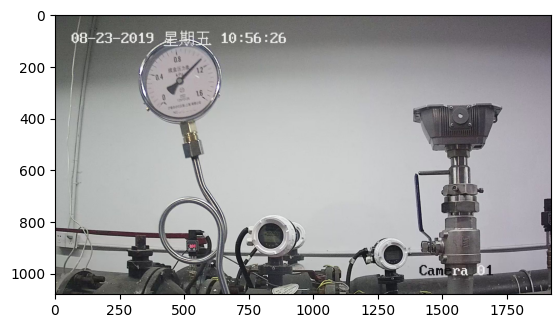

In [52]:

img_file = f"data/meter_test/20190822_123.jpg"
det_model_path = f"model/meter_det_model/model.pdmodel"
det_model_shape = {'image': [1, 3, 608, 608], 'im_shape': [1, 2], 'scale_factor': [1, 2]}
seg_model_path = f"model/meter_seg_model/model.pdmodel"
seg_model_shape = {'image': [ov.Dimension(1, 2), 3, 512, 512]}

erode_kernel = 4
score_threshold = 0.5
seg_batch_size = 2
input_shape = 608

# Intialize the model objects
detector = Model(det_model_path, det_model_shape)
segmenter = Model(seg_model_path, seg_model_shape)

# Visulize a original input photo
image = cv2.imread(img_file)
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(rgb_image)

The detection result image has been saved as "detection_results.jpg" in data


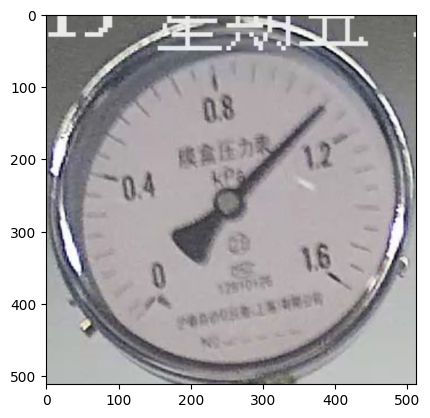

In [53]:

im_shape = np.array([[input_shape, input_shape]]).astype('float32')
scale_factor = np.array([[1, 2]]).astype('float32')
input_image = det_preprocess(image, input_shape)
inputs_dict = {'image': input_image, "im_shape": im_shape, "scale_factor": scale_factor}

det_results = detector.predict(inputs_dict)

filtered_results = filter_bboxes(det_results, score_threshold)

scale_x = image.shape[1] / input_shape * 2
scale_y = image.shape[0] / input_shape

roi_imgs, loc = roi_crop(image, filtered_results, scale_x, scale_y)
roi_imgs, resize_imgs = roi_process(roi_imgs, METER_SHAPE)

if len(resize_imgs) == 2:
    roi_stack = np.hstack([resize_imgs[0], resize_imgs[1]])
else:
    roi_stack = resize_imgs[0]

if cv2.imwrite(f"data/detection_results.jpg", roi_stack):
    print("The detection result image has been saved as \"detection_results.jpg\" in data")
    plt.imshow(cv2.cvtColor(roi_stack, cv2.COLOR_BGR2RGB))

The segmentation result image has been saved as "segmentation_results.jpg" in data


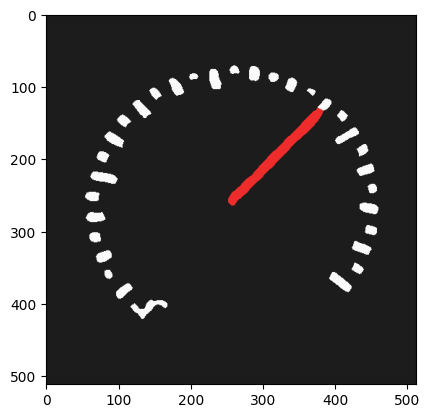

In [54]:
seg_results = list()
num_imgs = len(roi_imgs)

# Run meter segmentation model on all detected meters
for i in range(0, num_imgs, seg_batch_size):
    batch = roi_imgs[i : min(num_imgs, i + seg_batch_size)]
    seg_result = segmenter.predict({"image": np.array(batch)})
    seg_results.extend(seg_result)
results = []
for i in range(len(seg_results)):
    results.append(np.argmax(seg_results[i], axis=0)) 
seg_results = erode(results, erode_kernel)

# Create the pictures of segmentation results
if len(resize_imgs) == 2:
    mask_stack = np.hstack([segmentation_map_to_image(seg_results[0], COLORMAP), 
                            segmentation_map_to_image(seg_results[1], COLORMAP)])
else:
    mask_stack = segmentation_map_to_image(seg_results[0], COLORMAP)

if cv2.imwrite(f"data/segmentation_results.jpg", cv2.cvtColor(mask_stack, cv2.COLOR_RGB2BGR)):
    print("The segmentation result image has been saved as \"segmentation_results.jpg\" in data")
    plt.imshow(mask_stack)

The rectangle_meters result image has been saved as "rectangle_meters.jpg" in data


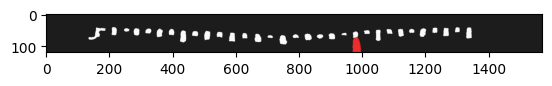

In [55]:
# Find the pointer location in scale map and calculate the meters reading 
rectangle_meters = circle_to_rectangle(seg_results)
line_scales, line_pointers = rectangle_to_line(rectangle_meters)
binaried_scales = mean_binarization(line_scales)
binaried_pointers = mean_binarization(line_pointers)
scale_locations = locate_scale(binaried_scales)
pointer_locations = locate_pointer(binaried_pointers)
pointed_scales = get_relative_location(scale_locations, pointer_locations)
meter_readings = calculate_reading(pointed_scales)

# Plot the rectangle meters
if len(rectangle_meters) == 2:
    rectangle_meters_stack = np.hstack([segmentation_map_to_image(rectangle_meters[0], COLORMAP),
                                        segmentation_map_to_image(rectangle_meters[1], COLORMAP)])
else:
    rectangle_meters_stack = segmentation_map_to_image(rectangle_meters[0], COLORMAP)

if cv2.imwrite(f"data/rectangle_meters.jpg", cv2.cvtColor(rectangle_meters_stack, cv2.COLOR_RGB2BGR)):
    print("The rectangle_meters result image has been saved as \"rectangle_meters.jpg\" in data")
    plt.imshow(rectangle_meters_stack)

Meter 1: 1.106
The reading results image has been saved as "reading_results.jpg" in data


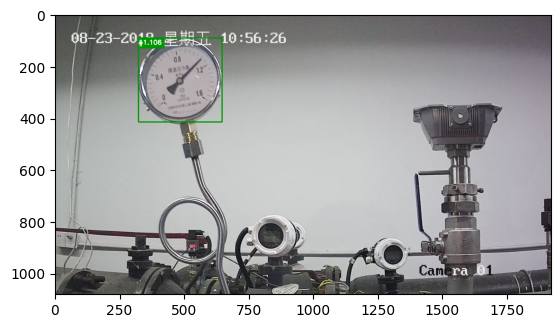

In [56]:
# Create a final result photo with reading
for i in range(len(meter_readings)):
    print("Meter {}: {:.3f}".format(i + 1, meter_readings[i]))
    
result_image = image.copy()
for i in range(len(loc)):
    cv2.rectangle(result_image,(loc[i][0], loc[i][1]), (loc[i][2], loc[i][3]), (0, 150, 0), 3)
    font = cv2.FONT_HERSHEY_SIMPLEX
    cv2.rectangle(result_image, (loc[i][0], loc[i][1]), (loc[i][0] + 100, loc[i][1] + 40), (0, 150, 0), -1)
    cv2.putText(result_image, "#{:.3f}".format(meter_readings[i]), (loc[i][0],loc[i][1] + 25), font, 0.8, (255, 255, 255), 2, cv2.LINE_AA)
if cv2.imwrite(f"data/reading_results.jpg", result_image):
    print("The reading results image has been saved as \"reading_results.jpg\" in data")
    plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))

Meter 1: 1.101


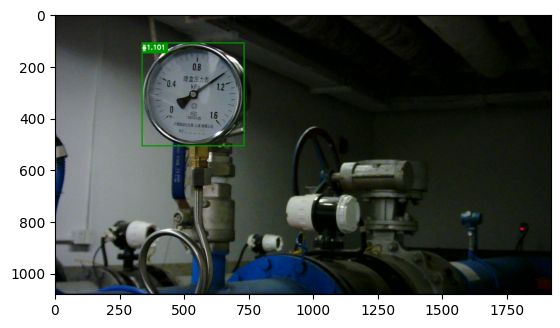

In [26]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_file = "data/meter_test/20190827144452222.jpg"
det_model_path = "model/meter_det_model/model.pdmodel"
det_model_shape = {'image': [1, 3, 608, 608], 'im_shape': [1, 2], 'scale_factor': [1, 2]}
seg_model_path = "model/meter_seg_model/model.pdmodel"
seg_model_shape = {'image': [1, 3, 512, 512]}

erode_kernel = 4
score_threshold = 0.5
input_shape = 608
#初始化模型对象
detector = Model(det_model_path, det_model_shape)
segmenter = Model(seg_model_path, seg_model_shape)
#加载并预处理输入图像
image = cv2.imread(img_file)
im_shape = np.array([[input_shape, input_shape]]).astype('float32')
scale_factor = np.array([[1, 2]]).astype('float32')
input_image = det_preprocess(image, input_shape)
inputs_dict = {'image': input_image, "im_shape": im_shape, "scale_factor": scale_factor}

#运行仪表检测模型
det_results = detector.predict(inputs_dict)
filtered_results = filter_bboxes(det_results, score_threshold)

#准备电表分段模型的输入数据
scale_x = image.shape[1] / input_shape * 2
scale_y = image.shape[0] / input_shape
roi_imgs, loc = roi_crop(image, filtered_results, scale_x, scale_y)
roi_imgs, resize_imgs = roi_process(roi_imgs, (512, 512))

#保存检测结果图像
roi_stack = np.hstack(resize_imgs) if len(resize_imgs) > 1 else resize_imgs[0]
cv2.imwrite("data/detection_results.jpg", roi_stack)
#运行仪表分段模型
seg_results = [segmenter.predict({"image": np.array([img])})[0] for img in roi_imgs]
seg_results = [np.argmax(res, axis=0) for res in seg_results]
seg_results = erode(seg_results, erode_kernel)
#保存分割结果图像
mask_stack = np.hstack([segmentation_map_to_image(res, COLORMAP) for res in seg_results])
cv2.imwrite("data/segmentation_results.jpg", cv2.cvtColor(mask_stack, cv2.COLOR_RGB2BGR))
#将分割结果进一步进行二值化处理
rectangle_meters = circle_to_rectangle(seg_results)
line_scales, line_pointers = rectangle_to_line(rectangle_meters)
binaried_scales = mean_binarization(line_scales)
binaried_pointers = mean_binarization(line_pointers)
scale_locations = locate_scale(binaried_scales)
pointer_locations = locate_pointer(binaried_pointers)
pointed_scales = get_relative_location(scale_locations, pointer_locations)
meter_readings = calculate_reading(pointed_scales)
meter_readings = calculate_reading(pointed_scales)
#保存处理结果
if len(rectangle_meters) == 2:
    rectangle_meters_stack = np.hstack([segmentation_map_to_image(rectangle_meters[0], COLORMAP),
                                        segmentation_map_to_image(rectangle_meters[1], COLORMAP)])
else:
    rectangle_meters_stack = segmentation_map_to_image(rectangle_meters[0], COLORMAP)

cv2.imwrite(f"data/rectangle_meters.jpg", cv2.cvtColor(rectangle_meters_stack, cv2.COLOR_RGB2BGR))

#创建带有读数的最终结果照片
for i in range(len(meter_readings)):
    print("Meter {}: {:.3f}".format(i + 1, meter_readings[i]))
    
result_image = image.copy()
for i in range(len(loc)):
    cv2.rectangle(result_image,(loc[i][0], loc[i][1]), (loc[i][2], loc[i][3]), (0, 150, 0), 3)
    font = cv2.FONT_HERSHEY_SIMPLEX
    cv2.rectangle(result_image, (loc[i][0], loc[i][1]), (loc[i][0] + 100, loc[i][1] + 40), (0, 150, 0), -1)
    cv2.putText(result_image, "#{:.3f}".format(meter_readings[i]), (loc[i][0],loc[i][1] + 25), font, 0.8, (255, 255, 255), 2, cv2.LINE_AA)
if cv2.imwrite(f"data/reading_results.jpg", result_image):
    plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))



In [46]:
import tkinter as tk
import tkinter.filedialog
import cv2
import os

def choose_file():  # 选择文件
    selectFileName = tk.filedialog.askopenfilename(title='选择文件')
    e.set(selectFileName)

def show(e_entry):  # 显示图片
    file_path = e_entry.get()
    if not os.path.exists(file_path):
        print(f"File not found: {file_path}")
        return
    img = cv2.imread('file_path')
    if img is None:
        print(f"Failed to load image: {file_path}")
        return
    cv2.imshow("PICTURE", img)
    cv2.waitKey(0)

def window():
    root = tk.Tk()
    root.geometry('650x450+150+100')
    root.title('test')
    root.resizable(False, False)
    global e
    e = tk.StringVar()  # 文本输入框
    e_entry = tk.Entry(root, width=68, textvariable=e)
    e_entry.pack()

    # 选择文件控件
    sumbit_btn = tk.Button(root, text="选择文件", bg='yellow', command=choose_file)
    sumbit_btn.pack()

    # 展示文件控件
    show_btn = tk.Button(root, text='查看图片', bg='blue', command=lambda: show(e_entry))
    show_btn.pack()

    root.mainloop()

window()


Failed to load image: E:/基于PP-YOLO实现工业表计读数提取/data/reading_results.jpg
